# Walkthrough: `06_current_ltv.py` (Indexed LTV, Downward-Only LTV & State HPI Drawdowns)

### Simple Summary
**This script estimates each home's current value by scaling its origination value with state-level house price indexes (FHFA HPI), tracks both mark-to-market (`indexed`) and PRA Article 124D (`downward-only`) LTV bands, and identifies historical state HPI peak-to-trough crashes.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`mortgages_sample.duckdb` and `module2_sample.duckdb`) strictly **read-only in memory** and tests `compute_drawdown_episodes()` live without altering disk files.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. Origination Value</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">V0 = UPB0 / (LTV0 / 100)</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. HPI Drawdowns</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">Running peak max(HPI)</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Indexed vs. Down</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">min(V0, V_idx) valuation</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>
  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Crash Visual</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Worst state HPI falls</text>
</svg>
</div>

---
### 1. Computing Origination Property Values & Running State HPI Drawdowns
Under UK PRA Article 124D / Basel 3.1, property values used for Standardised risk weights cannot be marked up above origination (`downward-only`), while downturn falls must be tracked against running historical peaks. We attach the fixed `0.03%` sample DBs read-only and run `compute_drawdown_episodes()` live on state HPI series.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only LTV/HPI checks
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display
import matplotlib.ticker as mtick

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then insert scripts/ for importing 06_current_ltv
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 06_current_ltv and restore Jupyter inline plotting (module2_common sets Agg)
# Switch matplotlib backend back to inline and attach both sample DBs strictly READ_ONLY
ltv_mod = importlib.import_module("06_current_ltv")
FIXED_SAMPLE_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/00_data/mortgages_sample.duckdb"
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"

con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_SAMPLE_DB.as_posix()}' AS src (READ_ONLY)")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Recompute running-peak state HPI drawdown episodes live in memory
# Query src.macro_state_hpi_table and pass into ltv_mod.compute_drawdown_episodes()
hpi_df = con.execute("SELECT state, quarter_date, CAST(house_price_index_sa AS DOUBLE) AS house_price_index_sa FROM src.macro_state_hpi_table ORDER BY 1, 2").fetchdf()
ep_df = ltv_mod.compute_drawdown_episodes(hpi_df)
ep_df.sort_values("fall_pct", ascending=False).head(8)[["state", "peak_date", "trough_date", "recovery_date", "fall_pct", "exceeds_10pct_art124d", "exceeds_40pct_ref"]].round(2)

,state,peak_date,trough_date,recovery_date,fall_pct,exceeds_10pct_art124d,exceeds_40pct_ref
78,NV,2006-01-01,2011-10-01,2020-01-01,59.36,True,True
5,AZ,2006-10-01,2011-04-01,2019-01-01,49.66,True,True
7,CA,2006-01-01,2011-07-01,2019-07-01,47.10,True,True
30,FL,2006-04-01,2011-01-01,2019-04-01,46.57,True,True
44,ID,2007-04-01,2011-04-01,2016-10-01,32.40,True,False
60,MI,2005-07-01,2011-04-01,2017-04-01,31.77,True,False
85,OR,2007-04-01,2011-04-01,2015-10-01,28.61,True,False
88,RI,2006-04-01,2012-07-01,2019-07-01,28.37,True,False


Using the running historical peak (`max(HPI)` up to time `t`) captures the 2006–2012 crashes cleanly—NV, AZ, FL, and CA all fell more than **35%–55%**. Next, we compare `indexed` vs. `downward-only` portfolio LTV over time and visualize the worst state drawdowns.

---
### 2. Comparing Indexed vs. Downward-Only LTV & Plotting Worst State Falls
When house prices surge, `indexed` LTV falls sharply (creating equity cushion), whereas `downward-only` LTV stays anchored to `min(V_0, V_idx)`—so Basel 3.1 capital floors never treat unrealized price gains as lower risk. Below we compare December 2025 weighted-average LTVs under both rules and chart the top 10 state drawdowns.

,quarter_date,ltv_type,active_loans,wavg_ltv_pct,pct_neg_equity
0,2009-10-01,downward_only,3088,70.06,6.18
1,2009-10-01,indexed,3088,68.29,6.18
2,2025-10-01,downward_only,4724,63.83,0.06
3,2025-10-01,indexed,4724,50.50,NaN


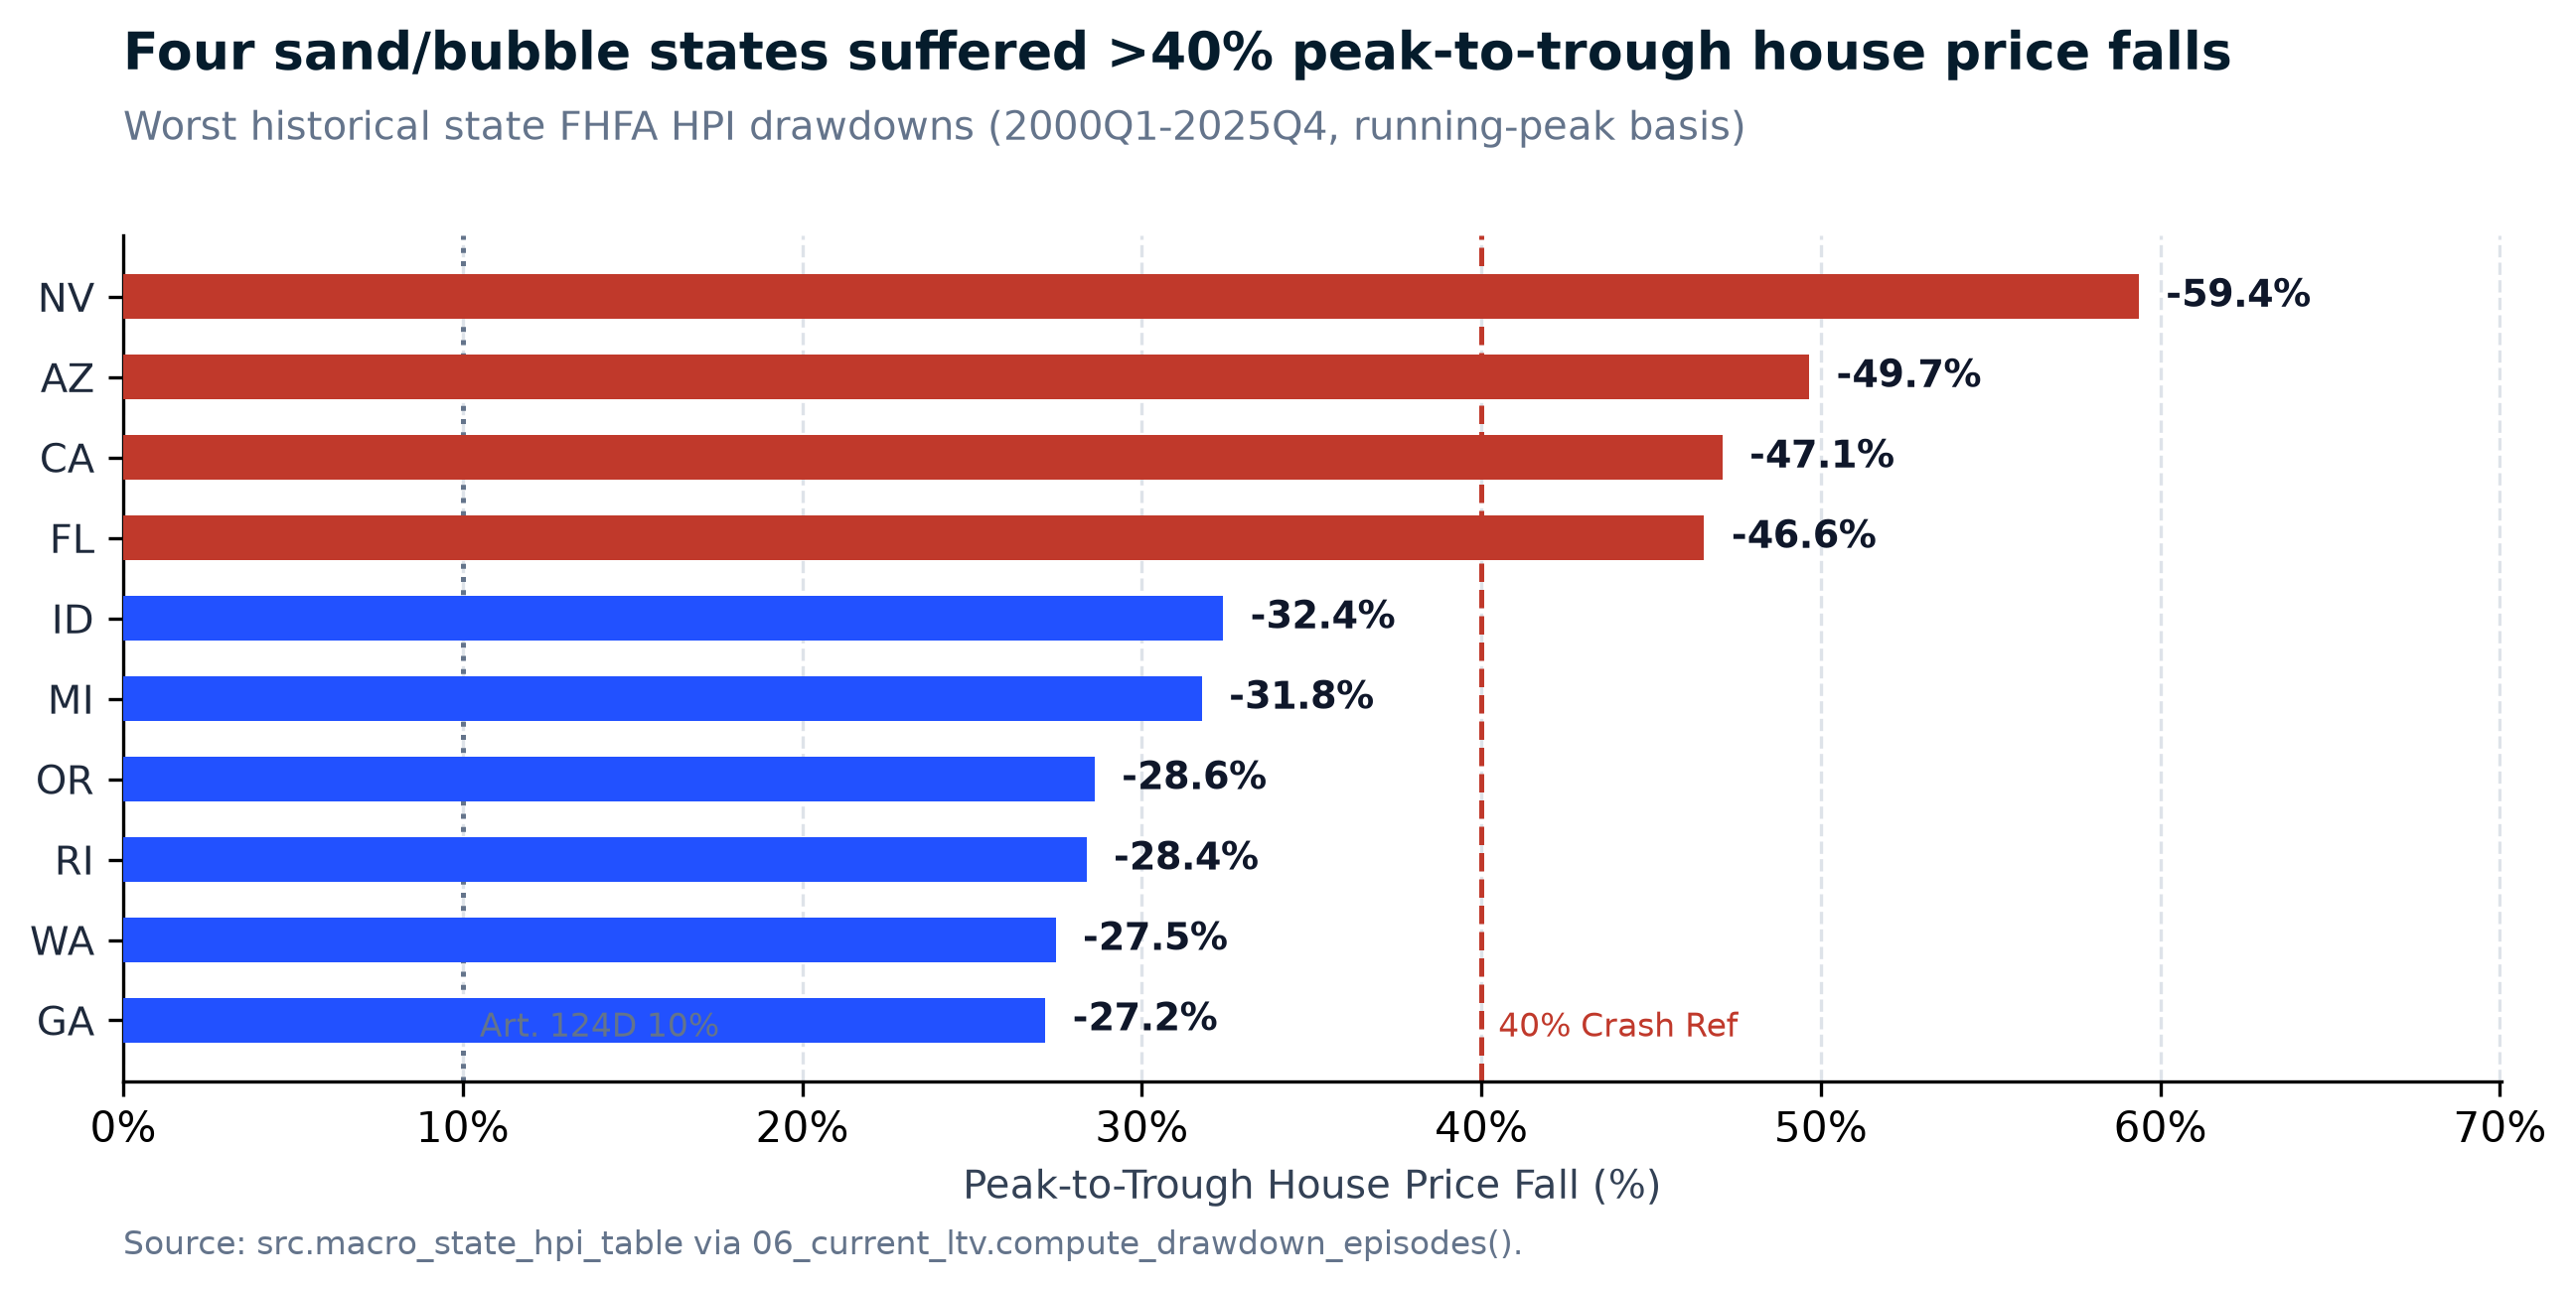

In [2]:
# Compare portfolio-weighted Indexed vs. Downward-Only LTV in 2009Q4 vs. 2025Q4
# Aggregate m2.current_ltv_mart weighted_ltv_num divided by balance across ltv_type
display(con.execute("""
    SELECT quarter_date, ltv_type, sum(loans)::BIGINT AS active_loans,
           round(sum(weighted_ltv_num) / sum(balance), 2) AS wavg_ltv_pct,
           round(100.0 * sum(balance) FILTER (WHERE ltv_band = '>100') / sum(balance), 2) AS pct_neg_equity
    FROM m2.current_ltv_mart
    WHERE quarter_date IN (DATE '2009-10-01', DATE '2025-10-01')
    GROUP BY 1, 2 ORDER BY 1, 2
""").fetchdf())

# Plot the top 10 worst state peak-to-trough HPI drawdowns at 300 dpi
# Select max fall_pct per state from ep_df and highlight >=40% reference crashes in coral
top10 = ep_df.groupby("state", as_index=False)["fall_pct"].max().sort_values("fall_pct", ascending=False).head(10)
colors = ["#C0392B" if v >= 40.0 else "#2251FF" for v in top10["fall_pct"]]

fig, ax = plt.subplots(figsize=(9.5, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.barh(range(len(top10)), top10["fall_pct"], color=colors, height=0.56, zorder=3)
for i, val in enumerate(top10["fall_pct"]):
    ax.text(val + 0.8, i, f"-{val:.1f}%", va="center", fontsize=9, fontweight="bold", color="#0F172A")
ax.axvline(10.0, color="#64748B", linestyle=":", linewidth=1.2, zorder=2)
ax.axvline(40.0, color="#C0392B", linestyle="--", linewidth=1.2, zorder=2)
ax.text(10.5, 9.2, "Art. 124D 10%", fontsize=8, color="#64748B")
ax.text(40.5, 9.2, "40% Crash Ref", fontsize=8, color="#C0392B")
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10["state"], fontsize=9.5, color="#1E293B")
ax.invert_yaxis()
ax.set_xlim(0, top10["fall_pct"].max() * 1.18)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("%.0f%%"))
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Peak-to-Trough House Price Fall (%)", fontsize=9.5, color="#334155")
fig.text(0.12, 0.94, "Four sand/bubble states suffered >40% peak-to-trough house price falls", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.12, 0.885, "Worst historical state FHFA HPI drawdowns (2000Q1-2025Q4, running-peak basis)", fontsize=9.5, color="#64748B")
fig.text(0.12, 0.015, "Source: src.macro_state_hpi_table via 06_current_ltv.compute_drawdown_episodes().", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.12, right=0.96, top=0.81, bottom=0.15)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release both attached read-only sample DB handles
con.close()

In 2025Q4, `indexed` weighted-average LTV sits nearly **25+ percentage points** below `downward-only` LTV—illustrating why UK rules keep capital conservative in booming housing markets. Next, `07_default_rate_history.py` builds the 12-month default rate time series and estimates Vasicek asset correlation.